In [ ]:
# importing necessary libraries
import os
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Image Processing
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img

# CATS AND DOGS DATASET

In [ ]:
# Loading the dataset
!pip install kaggle

# Create folder
!mkdir -p dogsvscats_dataset

# Download dataset
!kaggle datasets download -d princelv84/dogsvscats -p dogsvscats_dataset

# Unzip dataset
!unzip dogsvscats_dataset/dogsvscats.zip -d dogsvscats_dataset

Streaming output truncated to the last 5000 lines.
  inflating: dogsvscats_dataset/train/dogs/dog.4419.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.442.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4420.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4421.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4422.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4424.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4425.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4426.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4427.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4431.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4433.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4436.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4438.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4439.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.444.jpg  
  inflating: dogsvscats_dataset/train/dogs/dog.4440.jpg  
  inflating: dogsvscats

In [ ]:
# Remove zip
#!rm dogsvscats_dataset/dogsvscats.zip

In [ ]:
dataset_path = 'dogsvscats_dataset/train'

In [ ]:
os.listdir(dataset_path)

['dogs', 'cats']

In [ ]:
cats_path = os.path.join(dataset_path, 'cats')
dogs_path = os.path.join(dataset_path, 'dogs')

cat_images = os.listdir(cats_path)
dog_images = os.listdir(dogs_path)

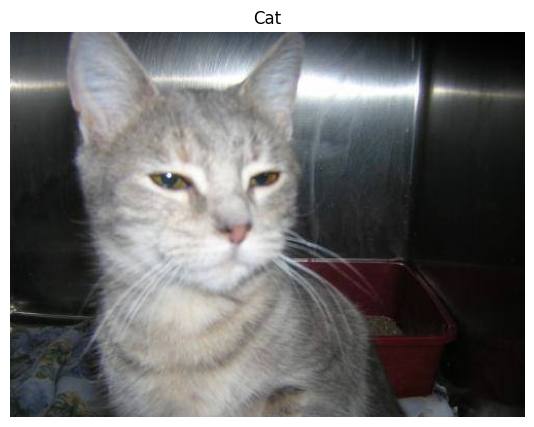

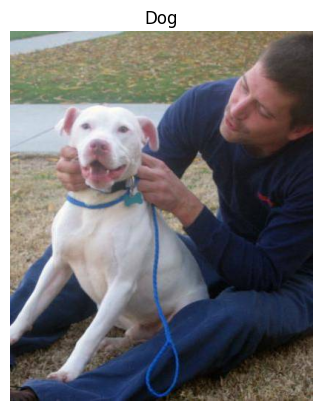

In [ ]:
plt.figure(figsize=(10,5))

plt.imshow(load_img(os.path.join(cats_path, cat_images[0])))
plt.title("Cat")
plt.axis('off')
plt.show()

plt.imshow(load_img(os.path.join(dogs_path, dog_images[0])))
plt.title("Dog")
plt.axis('off')
plt.show()

In [ ]:
img = load_img(os.path.join(cats_path, cat_images[1]))

print("Image Size:", img.size)

Image Size: (499, 375)


In [ ]:
from tensorflow.keras.preprocessing.image import img_to_array

img_array = img_to_array(img)

print("Image Shape:", img_array.shape)

Image Shape: (375, 499, 3)


In [ ]:
print(img_array[1])

[[ 96. 114.  88.]
 [ 65.  83.  57.]
 [ 37.  55.  33.]
 ...
 [ 68.  76.  78.]
 [ 35.  44.  43.]
 [ 83.  92.  89.]]


In [ ]:
# Load data
train_data = ImageDataGenerator(rescale=1./255).flow_from_directory(
    dataset_path,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary'
)

Found 20000 images belonging to 2 classes.


In [ ]:
model = Sequential()

model.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)))
model.add(MaxPooling2D(2,2))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
model.fit(train_data, epochs=5)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 579s 918ms/step - accuracy: 0.6757 - loss: 0.8399
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 593s 949ms/step - accuracy: 0.7861 - loss: 0.4569
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 584s 933ms/step - accuracy: 0.8723 - loss: 0.3018
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 594s 950ms/step - accuracy: 0.9291 - loss: 0.1858
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 583s 933ms/step - accuracy: 0.9599 - loss: 0.1176


In [ ]:
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 4000 images belonging to 2 classes.


In [ ]:
test_data = ImageDataGenerator(rescale=1./255).flow_from_directory(
    'dogsvscats_dataset/test',
    target_size=(150,150),
    batch_size=32,
    class_mode='binary'
)

test_loss, test_acc = model.evaluate(test_data)
print(f"Test Accuracy: {test_acc*100:.2f}%")

Found 5000 images belonging to 2 classes.
157/157 ━━━━━━━━━━━━━━━━━━━━ 41s 259ms/step - accuracy: 0.7284 - loss: 0.8308
Test Accuracy: 72.84%


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = 'mydog.jpg'   # your image path

img = image.load_img(img_path, target_size=(150,150))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

if prediction[0][0] > 0.5:
    print("Dog")
else:
    print("Cat")